Name: Teresa Leonez
USC ID: 9630346635

In [ ]:
# Import packages

In [75]:
# Import general helper packages
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import statistics

# Question 8a. packages
from scipy.stats import norm, lognorm
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Question 8b.
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split

In [4]:
# Question 8: Predicting Housing Prices with Linear Regression

In [5]:
# Import the dataseet as a pandas DataFrame
filepath = "student/student-mat.csv"
df = pd.read_csv(filepath, sep = ";")   

In [135]:
# Display missing value counts
print(df.isna().sum())

# Hidden missing value counts --> final grade recorded as 0
print("Instances where g3 = 0", (df["G3"] == 0).sum())

# Expected output = 38 students out of 395 instances show a 0 grade, possibly indicating drop out

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64
Instances where g3 = 0 38


In [6]:
# Select given features 
features = ['age',         # predictor
            'studytime',   # predictor
            'schoolsup',   # predictor
            'goout',       # predictor
            'Dalc',        # predictor
            'Walc',        # predictor
            'health',      # predictor
            'absences',    # predictor
            'G3'           # target variable
           ]

cleaned_df = df[features].copy()  # Create new df with selected features

# Encode feature 'schoolsup' as binary 1=yes, 0=no
def binary_feature(df, feature):
    df[feature] = df[feature].map({'yes': 1, 'no': 0})

# Call binary feature function with 'schoolsup'
binary_feature(cleaned_df, 'schoolsup')  

# Average values in 'Walc' and 'Dalc' columns and insert new column 'alc' 
cleaned_df.insert(5, 'alc', (cleaned_df['Walc'] + cleaned_df['Dalc']) / 2)  

# Remove Dalc and Walc columns
cleaned_df = cleaned_df.drop(columns=['Walc', 'Dalc'])  

# Display first 5 rows of pre-processed dataset
print(cleaned_df.head(5))  

   age  studytime  schoolsup  goout  alc  health  absences  G3
0   18          2          1      4  1.0       3         6   6
1   17          2          0      3  1.0       3         4   6
2   15          2          1      2  2.5       3        10  10
3   15          3          0      2  1.0       5         2  15
4   16          2          0      2  1.5       5         4  10


In [125]:
cleaned_df

,age,studytime,schoolsup,goout,alc,health,absences,G3
0,18,2,1,4,1.0,3,6,6
1,17,2,0,3,1.0,3,4,6
2,15,2,1,2,2.5,3,10,10
3,15,3,0,2,1.0,5,2,15
4,16,2,0,2,1.5,5,4,10
...,...,...,...,...,...,...,...,...
390,20,2,0,4,4.5,4,11,9
391,17,1,0,5,3.5,2,3,16
392,21,1,0,3,3.0,3,3,7
393,18,1,0,1,3.5,5,0,10


age IQR range: (13.0, 21.0)
age outliers: 1

studytime IQR range: (-0.5, 3.5)
studytime outliers: 27

schoolsup IQR range: (0.0, 0.0)
schoolsup outliers: 51

goout IQR range: (-1.0, 7.0)
goout outliers: 0

alc IQR range: (-1.25, 4.75)
alc outliers: 9

health IQR range: (0.0, 8.0)
health outliers: 0

absences IQR range: (-12.0, 20.0)
absences outliers: 15



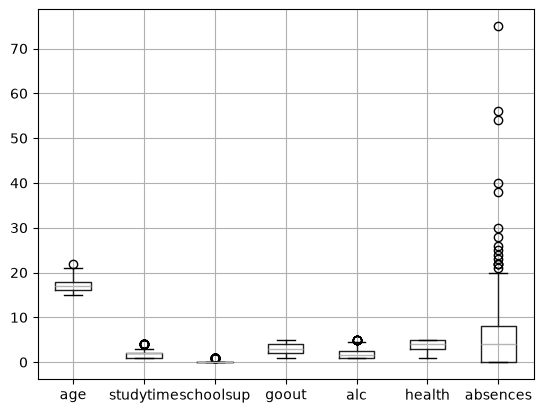

In [132]:
# Question 8a.iii. Find the outliers using IQR Method

# Create list of independent variables
ind_var = ['age', 'studytime', 'schoolsup', 'goout', 'alc', 'health', 'absences']

# Loop through independent variables to find IQR range
for var in ind_var:    
    q1, q3 = np.percentile(cleaned_df[var], [25, 75])    # Calculate q1 and q3 points using numpy
    iqr_value = q3 - q1
    upper = q3 + (1.5*iqr_value)   # Find upper bound of IQR
    lower = q1 - (1.5*iqr_value)   # Find lower bound of IQR
    print(f"{var} IQR range: ({lower}, {upper})")
    
    # Outlier detection using IQR (x > upper IQR or x < lower IQR)
    outliers = [] 
    for value in cleaned_df[var]:
        if value < lower or value > upper:
            outliers.append(value)  # Add detected outlier to list
    number = len(outliers)
    print(f"{var} outliers: {number}\n")

# Visualization for outliers
cleaned_df[ind_var].boxplot()
plt.show()

Note: Since 'schoolsup' is binary, running outlier detection using IQR results in all "0" answers counting as outliers. Variables 'studytime' 'goout' and 'alc' have negative lower bounds, which are not possible in this case.

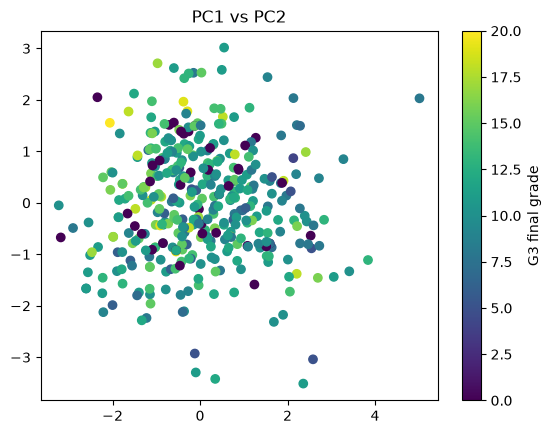

In [8]:
# Question 8.a.iv. Standardize and run PCA on dataset
X = cleaned_df[ind_var]       # Run Scaler on independent features
X_scaled = StandardScaler().fit_transform(X)

# use PCA from sklearn
pca = PCA()
pc_scores = pca.fit_transform(X_scaled)
PC1 = pc_scores[:, 0]  # PC1 is first column
PC2 = pc_scores[:, 1]  # PC2 is second column

# Plot PC1 vs PC 2 as scatterplot
plt.scatter(PC1, PC2, c=cleaned_df['G3'], cmap='viridis')    # Plot using different colors for G3 grades
plt.colorbar(label='G3 final grade')
plt.title("PC1 vs PC2")
plt.show()

There doesn't seem to be a clear boundary predictor in the PC1 vs PC2 scatterplot separating student's final grades based on the features given. The plot shows mixed colored dots, ranging from low to high mixed in with each other.

In [9]:
# Inspect component loadings
comp_loadings = pd.DataFrame(pca.components_, columns=X.columns, index=[f"PC{i+1}" for i in range(pca.n_components_)])
print("Principal Component Loadings")
print(comp_loadings.loc[['PC1', 'PC2']])

# Get maximum value in PC1 Loadings 
pc1_main_feature = comp_loadings.loc['PC1'].abs().idxmax()   
print(f"PC1 max feature: {pc1_main_feature}: {comp_loadings.loc['PC1', pc1_main_feature]}")

# Get maximum value in PC2 Loadings 
pc2_main_feature = comp_loadings.loc['PC2'].abs().idxmax()   
print(f"PC2 max feature: {pc2_main_feature}: {comp_loadings.loc['PC2', pc2_main_feature]}")

Principal Component Loadings
         age  studytime  schoolsup     goout       alc    health  absences
PC1  0.38194  -0.329734  -0.248184  0.493755  0.595871  0.080545  0.280106
PC2  0.58926   0.385671  -0.464202 -0.139613 -0.273677 -0.400925  0.182798
PC1 max feature: alc: 0.5958705209299794
PC2 max feature: age: 0.5892603671186117


Answer: The principal component loadings showed that for PC1, alcohol consumption had the largest contribution, while 'age' showed the largest contribution for PC2.

In [ ]:
# (b) Linear Regression

In [39]:
# Split data into training and testing set with 80:20 ratio, using random seed 552

In [115]:
X = cleaned_df[ind_var]   # Pull x features from cleaned df
y = cleaned_df['G3']      # Pull target from cleaned df 

# Split data into training and testing set with 80/20 ratio
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=552)

scaler = StandardScaler()    # Scale model 
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [117]:
# Build linear regression model with train set
linreg_model = LinearRegression().fit(X_train, y_train)   # Fit the linreg model with training data
linreg_model_scaled = LinearRegression().fit(X_train_scaled, y_train)   # Fit linreg model with scaled data for comparison
linreg_coef, linreg_intercept = linreg_model.coef_, linreg_model.intercept_
linreg_s_coef, linreg_s_intercept = linreg_model_scaled.coef_, linreg_model_scaled.intercept_

In [118]:
# Build Linear Regression Model with Ridge Regularization

# Fit ridge using given alpha = 0.1
alpha = .1
ridge_model = Ridge(alpha=alpha).fit(X_train_scaled, y_train)

In [119]:
# Build Linear Regression Model with Lasso Regularization
lasso_model = Lasso(alpha=alpha).fit(X_train_scaled, y_train)

# Check dropped features
feature_summary = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lasso_model.coef_
})

# Features with coef 0 --> dropped features
dropped_features_table = feature_summary[feature_summary['Coefficient'] == 0.0]
dropped_features = dropped_features_table['Feature'].to_string(index=False)

# Display dropped features
print(f"Dropped features: {dropped_features}")

Dropped features: alc


In [ ]:
# Test all three models on the test set

In [127]:
# Create df to store model metrics
metrics_df = pd.DataFrame(
    index=["Linear Reg", "Ridge Reg", "Lasso"],
    columns=["MAE", "RME", "R2"]
)

Residual Plot for Lin Reg Model


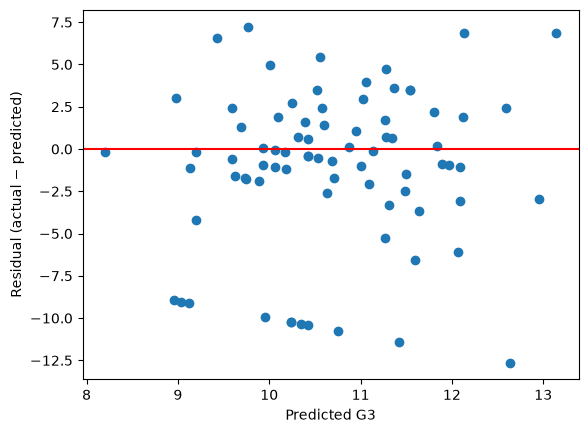

In [137]:
# Test on Plain Linear Regression model
y_pred = linreg_model.predict(X_test)   # Test on unscaled data 
y_pred_scaled = linreg_model_scaled.predict(X_test_scaled)   # Test on scaled data

# Get model metrics on both scaled and unscaled model

#Mean Absolute error
mae_linreg = mean_absolute_error(y_test,y_pred)
mae_linreg_s = mean_absolute_error(y_test,y_pred_scaled)

#Root mean squared error
rmse_linreg = root_mean_squared_error(y_test, y_pred)
rmse_linreg_s = root_mean_squared_error(y_test, y_pred_scaled)

#R2
r2_linreg = r2_score(y_test, y_pred)
r2_linreg_s = r2_score(y_test, y_pred_scaled)

mae_linreg, rmse_linreg, r2_linreg

# Add metrics to summary table
metrics_df.loc["Linear Reg"] = [mae_linreg, rmse_linreg, r2_linreg]  

# Plot residual visualization
residual = y_test - y_pred

print("Residual Plot for Lin Reg Model")
plt.scatter(y_pred, residual)
plt.axhline(0, color="red")
plt.xlabel("Predicted G3")
plt.ylabel("Residual (actual − predicted)")
plt.show()

Residual Plot for Ridge Reg Model


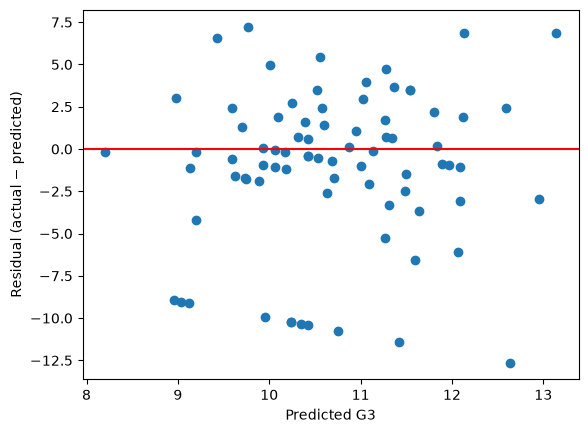

In [138]:
# Test on Ridge Regularization Set
y_pred = ridge_model.predict(X_test_scaled)  # Test on scaled data

# Get model metrics
mae_ridge = mean_absolute_error(y_test,y_pred)
rmse_ridge = root_mean_squared_error(y_test, y_pred)
r2_ridge = r2_score(y_test, y_pred)
mae_ridge, rmse_ridge, r2_ridge

metrics_df.loc["Ridge Reg"] = [mae_ridge, rmse_ridge, r2_ridge]  

# Plot residual visualization
residual = y_test - y_pred

print("Residual Plot for Ridge Reg Model")
plt.scatter(y_pred, residual)
plt.axhline(0, color="red")
plt.xlabel("Predicted G3")
plt.ylabel("Residual (actual − predicted)")
plt.show()

Residual Plot for Lasso Model


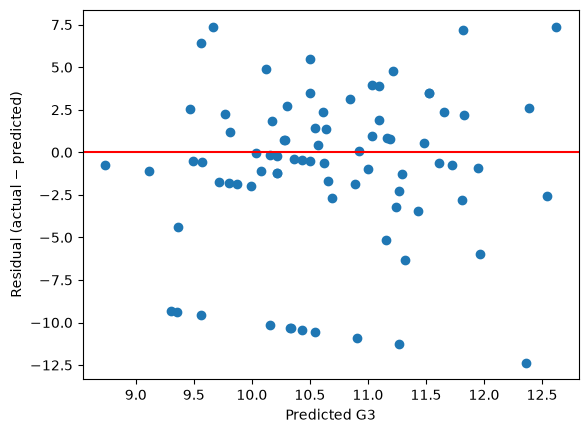

In [139]:
# Test on Lasso Set
y_pred = lasso_model.predict(X_test_scaled)  # Test on scaled data

# Get model metrics
mae_lasso = mean_absolute_error(y_test,y_pred)
rmse_lasso = root_mean_squared_error(y_test, y_pred)
r2_lasso = r2_score(y_test, y_pred)
mae_lasso, rmse_lasso, r2_lasso

metrics_df.loc["Lasso"] = [mae_lasso, rmse_lasso, r2_lasso] 

# Plot residual visualization
residual = y_test - y_pred

print("Residual Plot for Lasso Model")
plt.scatter(y_pred, residual)
plt.axhline(0, color="red")
plt.xlabel("Predicted G3")
plt.ylabel("Residual (actual − predicted)")
plt.show()

In [126]:
# Display summary table to compare the three models
metrics_df

,MAE,RME,R2
Linear Reg,3.418009,4.755812,0.028177
Linear Reg Scaled,3.418009,4.755812,0.028177
Ridge Reg,3.418064,4.75586,0.028157
Lasso,3.447338,4.794612,0.012255


In [113]:
# Get best MAE, RMSE, R2
best_mae_value = round(metrics_df["MAE"].min(), 4)
best_rmse_value= round(metrics_df["RME"].min(), 4)
best_r2_value= round(metrics_df["R2"].max(), 4)

print("Best MAE:", metrics_df["MAE"].idxmin(), best_mae_value)
print("Best RMSE:", metrics_df["RME"].idxmin(), best_rmse_value)
print("Best R2:", metrics_df["R2"].idxmax(), best_r2_value)

Best MAE: Linear Reg 3.418
Best RMSE: Linear Reg 4.7558
Best R2: Linear Reg 0.0282


# Interpret the results
All three models result in low r^2 values (linreg& ridge reg =.028, lasso =.012) indicating the models explain less than 2% of the variation in final grades based on the given data. The metrics for all 3 models (Linear regression, with ridge regularization, and with lasso) results are relatively similar, with MAE only differentiating by .03, and RMSE only different by .04. 

In [131]:
# Build coefficient df with respective values
coef_df = pd.DataFrame({
    "Linear Reg": linreg_model.coef_,
    "Linear Reg Scaled": linreg_model_scaled.coef_,
    "Ridge Reg": ridge_model.coef_,
    "Lasso": lasso_model.coef_,
}, index=X_train.columns)

# Add intercepts to table
coef_df.loc["intercept"] = [linreg_model.intercept_, linreg_model_scaled.intercept_, ridge_model.intercept_, lasso_model.intercept_]

print("Model Coefficient and Intercept Table")
coef_df


Model Coefficient and Intercept Table


,Linear Reg,Linear Reg Scaled,Ridge Reg,Lasso
age,-0.612885,-0.785327,-0.784976,-0.630916
studytime,0.530689,0.449134,0.448974,0.351270
schoolsup,-2.035251,-0.717780,-0.717459,-0.570052
goout,-0.523910,-0.570108,-0.569917,-0.477690
alc,0.037412,0.036301,0.036145,-0.000000
health,-0.175237,-0.245802,-0.245702,-0.141941
absences,0.024121,0.197840,0.197726,0.070762
intercept,22.088189,10.613924,10.613924,10.613924


# Question 8.a.vi. 
The results show a negative correlation on final grade with variables 'age', 'schoolsup', 'goout', and 'health', with age having the highest absolute correlation coefficient. This indicates the variable with highest effect on final grade based on the given dataset is age: the older a student is, we can expect their final grade to drop lower by rougly .70 points. We can expect the student's final grade to drop by .72 points for every additional hour of studytime, possibly due to students who struggle with coursework needing more time to study. The more students go out, the lower their final grade drops. School supervision also showed a negative correlation , as a binary variable, indicating students needing additional supervision can expect to have a lower final grade than students without. Interestingly, the better a student's health score was, the lower their final grade dropped, but this correlation coefficient is weak.

Variables with positive correlations include 'studytime', 'alc', 'absences'. Studytime shows a positive correlation of .44, indicating every hour of additional study can expect the student's final grade to go up by .44. In the lasso model, alcohol was dropped, and in linear and ridge, the final coefficient was positive but low, indicating alcohol has very little effect on the final grade. The more absences a student had, the higher the expected grade was, but only by very little. 

However given the low R^2 overall, the dependent variable overall is not well predicted by the independent variables in any of these models.

# Question 8.b.vii. 
In Linear Regression, the coefficients are not penalized, and larger differences between feature coefficients are not scaled to their weight/effect on target. For example, 'schoolsup' has a negative coefficient of 2.04 unscaled, but scaled is -.72. To demonstrate the difference, I included both scaled and unscaled versions (also because the question did not specify which to use) 

In Ridge Regularization, larger coefficients are regularized towards 0, without dropping any, and all coefficients are weighted between 0 and 1. In Lasso, coefficients are regularized with lowest features dropped. 

The results indicate a very weak correlation overall (low R2) for the features and the predicted y (final grade), indicating weak model strength across the board. 

# Question 8.b.viii
Increasing alpha does not necessarily increase performance metrics. Adjusting alpha (in this case 0.1) will generally follow a U shape curve, lowering the error as it increases on training data, but increasing error as it overfits to the training data, resulting in increasing error on test data after a certain optimal alpha is reached.

# Question 8.b.vix.
I would suggest implementing polynomial degree features to look at features that may be interacting with each other, such as 'alc' and 'go out', and create a new feature column accounting for their interaction (example: alc * go out), as well as adding higher degree exponents such as age^2 to look at non-linear relationships. We also dropped many of the original 30 features, and got a very low R^2, I would run ridge and lasso again on a wider net of features to begin, before selecting final features to see if there are better combinations to result in stronger model.